# N145 — Constrained H1 prediction of loss and RankMe

This experiment returns to the N106/N107 one-image, one-step health-state
predictor. It asks whether an action-conditioned predictor can identify an
update that reduces reconstruction loss AND increases representation rank.
Health is the evaluation objective in this experiment. Linear probes, kNN,
fine-tuning, task labels and task-retention guards are disabled. No task panels
are loaded. This does not establish downstream task improvement.

## Exact measurements and decision

Each candidate is one update on the incoming image. Actions are skip, quarter
and full of the ORIGINAL N107 nominal LR 0.0001: {0, 0.000025, 0.0001}.
Skip calls neither backward nor optimizer.step. There is no online candidate
training, performance rollback, exploration override, quota or forced update.

L is current-image reconstruction loss under fixed assay pixels and MAE masks,
separate from the seeded training view. R is raw, uncentered singular-spectrum
RankMe on the latest 256 received images, INCLUDING the incoming image. Before
and after use exactly the same window membership; all embeddings are freshly
encoded by the respective model. A single pooled image vector is not a valid
population RankMe signal. No patch-RankMe substitution is made.

Each independent partition/arm receives 255 images without training to fill
the causal window. The first measured origin is arrival 256. The window then
advances on every arrival, including skips. Window replacement is not an
update gain. No old fixed-bank image bootstraps the rolling window.

The predictor outputs changes in L and R, then adds the measured baseline.
Hold is structurally identity on the current measurement population. The next
incoming image can have a different baseline even after a hold.

Positive actions must satisfy BOTH strict inequalities:

- current L minus predicted post-update L > 0.001;
- predicted post-update R minus current R > 5 raw rank units.

Among feasible actions minimize S = predicted_L/current_L + current_R/predicted_R.
This explicitly corrects the apparent denominator typos in the supervisor notes.
Hold has score 2. Exact ties choose the smaller rate. Nonphysical predictions are
ineligible. No feasible candidate means hold. The literal threshold 5 is NOT
changed to 5%, 0.005, or normalized units. A no-op measurement tolerance is used
only to recognize floating-point RankMe bounds, never to loosen either gain.

These are predicted constraints, not a guarantee of actual monotonic health.
Realized health violations stay in the trajectory and train the adaptive
predictor. Nonfinite computation halts with the last committed state preserved.

## Calibration and evaluation separation

Reuse N106's original pre-96k parent and whole-clip partition: 30 training clips
(2,880 arrivals), six validation clips (576), six test clips (576), and 958
reserved online clips (91,968). This is previously inspected development video,
not a new independent benchmark. Every partition and arm starts from the same
original learner/Adam parent; calibration-trained neural weights never transfer.

After 255 window-fill arrivals per partition there are 2,625 / 321 / 321 matched
origins. Each origin has the exact identity hold outcome and two actual positive
branches restored from the same full state with paired training-view randomness.
A predeclared balanced mixed action supplies the continuing calibration state.
Both measured positive actions supply offline labels. The other branch is
discarded; this offline branch collection is not deployment-time rollback.

The 29-coordinate context contains current and two prior post-update (L,R)
pairs, two prior actions, N106's eleven raw-image statistics, an eight-dimensional
fixed-seed projection of the current image embedding, its norm and cosine to
the current-window mean embedding. No task feedback, clip identifiers, arrival
clock, screening gradients or optimizer summaries enter prediction. Old health
coefficients and targets are NOT reused.

Use the N106-style quadratic-rate ridge, train-only input/target normalization,
validation selection of alpha in {1,10,100}, then freeze before collecting test.
Select by mean squared positive-action prediction error normalized by TRAIN
delta scales. No refit on validation/test. Online adaptation, when deployed,
starts from those TRAIN sufficient statistics, has a 256-successful-update
forgetting half-life, and learns only actual executed positive-action feedback.
Frozen shadows predict the same selected states/actions for paired comparisons.

## Predeclared deployment gate and queue

Collect all three partitions and report held-out qualification regardless of
whether the literal threshold is feasible. Deploy only if VALIDATION contains
at least one actually feasible positive branch AND one correctly predicted
feasible positive branch. This is a minimal feasibility gate, not an efficacy
claim. Test does not select settings or determine deployment.

If the gate fails, finish with `complete_infeasible_threshold` or
`complete_predictor_unqualified`. Do not waste a full online comparison on a
known empty feasible set; do not silently lower thresholds. The completed
notebook reports the failure and measured gain scales explicitly.

If the gate passes, run adaptive H1, frozen H1, freeze, always-quarter and
always-full sequentially on all 91,968 reserved arrivals. Baselines intentionally
do not enforce the controller constraints. All share the same original parent,
ordered pixels and per-image training seeds. One randomness family is exploratory.
No best-checkpoint selection. Random-budget and trailing-image-loss ablations
remain follow-ups, not hidden additions to this run.

## Reports and reproducibility

Fixed-bank reconstruction, RankMe, normalized variance/covariance, CKA drift,
cosine drift and norm are evaluated at the parent, every 384 arrivals and ends.
The fixed bank is never trained on or used by the controller. The recent-window
rank and paired current-image loss remain separate from these common-population
evaluation trajectories. Report positive-action RMSE/MAE versus persistence,
joint-feasibility precision/recall, physical prediction failures, actual
constraint violations, update counts, selected rates, and costs. Identity skips
must not dilute forecast error. An empty feasible set has undefined recall,
not perfect recall. Correlated origins are not independent experimental replicas.

The worker saves complete learner/optimizer/RNG state and trace every 96
arrivals, retains two generations within its own experiment directory, and
updates the saved notebook, Markdown and HTML after each commit. The local HTML
reloads every 20 seconds. Resume verifies frozen input/source hashes. A stop
request or <1 GiB free disk ends after a safe commit. Failures are visible in
status.json and the notebook. No automatic restarts or model-policy changes.

GPU preflight verifies repeated assay identity, matched parents, hold identity,
exact uninterrupted-versus-resumed offline collection, and exact online
adaptive/freeze resumption. A permissive threshold is used ONLY in a clearly
separate engineering check to exercise adaptive feedback; the scientific run
retains 0.001 and 5. Engineering updates are reported separately. No scientific
test outcomes are used during preflight.


## Incoming-image plots (reporting amendment)

The live report also plots the actual current-image reconstruction loss before and after the retained action, its paired loss change, rolling-window RankMe before and after and its paired change, and the current-image embedding norm and cosine to the window mean. Norm and cosine are pre-action measurements; post-action values were not recorded. RankMe is explicitly a 256-image population measurement, not a rank assigned to one image vector. Curves show every measured arrival from 256 onward, including zero changes on skips; no smoothing or prediction substitution. Offline after-values follow the predeclared mixed calibration action, not the constrained policy. Changing images/windows can move baseline levels without a model update, so the paired-change panels isolate actual update effects. Fixed-bank plots remain separate.


Status: **complete_infeasible_threshold**. Updated UTC: `2026-11-04T10:58:00.100218+00:00`.

Calibration and held-out test complete. Deployment gate failed; no forced updates or automatic threshold relaxation.

| Path | Arrivals | Measured origins | Retained updates | Executed optimizer steps | Actually feasible branches | Max rank gain |
|---|---:|---:|---:|---:|---:|---:|
| offline/test | 576/576 | 321 | 214 | 642 | 0 | 0.0849058 |
| offline/train | 2880/2880 | 2625 | 1750 | 5250 | 0 | 0.241498 |
| offline/validation | 576/576 | 321 | 214 | 642 | 0 | 0.105442 |

Offline mixed-path updates collect response labels; they are not actions admitted by the constrained controller.

GPU/resume preflight: **passed**.

Completed engineering-path optimizer steps: 54. Scientific work is counted separately above.

Deployment gate: **not passed**. Validation has at least one genuinely feasible branch and one correctly predicted feasible branch.

Held-out qualification (skip excluded):

| Split | Positive branches | Actual feasible | Predicted feasible | True positive | Precision | Recall |
|---|---:|---:|---:|---:|---:|---:|
| train | 5250 | 0 | 0 | 0 | undefined | undefined |
| validation | 642 | 0 | 0 | 0 | undefined | undefined |
| test | 642 | 0 | 0 | 0 | undefined | undefined |

Costs (seconds; includes paired collection and all arms):

- measurement: 325.84
- training: 124.07
- prediction: 0.00
- adaptation: 0.00
- fixed_audit: 3.66

These counters exclude checkpoint/report overhead and engineering checks; collection cost is not deployment cost.


In [1]:
from pathlib import Path
import json
root = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\constrained-health-h1\\20261104-n145')
summary = json.loads((root / 'report-summary.json').read_text())
print(json.dumps(summary, indent=2))


{
  "status": {
    "stage": "complete_infeasible_threshold",
    "running": false,
    "pid": 14544,
    "updated_utc": "2026-11-04T10:58:00.100218+00:00",
    "explanation": "Calibration and held-out test complete. Deployment gate failed; no forced updates or automatic threshold relaxation."
  },
  "fit": {
    "alpha": 1.0,
    "candidates": {
      "1.0": {
        "normalized_mse": 2.6246084774208005,
        "validation": {
          "origins": 321,
          "positive_branches": 642,
          "actual_feasible": 0,
          "predicted_feasible": 0,
          "true_positive": 0,
          "precision": null,
          "recall": null,
          "max_rank_gain": 0.10544212247286255,
          "max_loss_gain": 0.057617902755737305,
          "by_action": {
            "0.25": {
              "rmse": [
                0.0035158705786802066,
                0.008637135251472708
              ],
              "mae": [
                0.0024294331805515498,
                0.00639886952

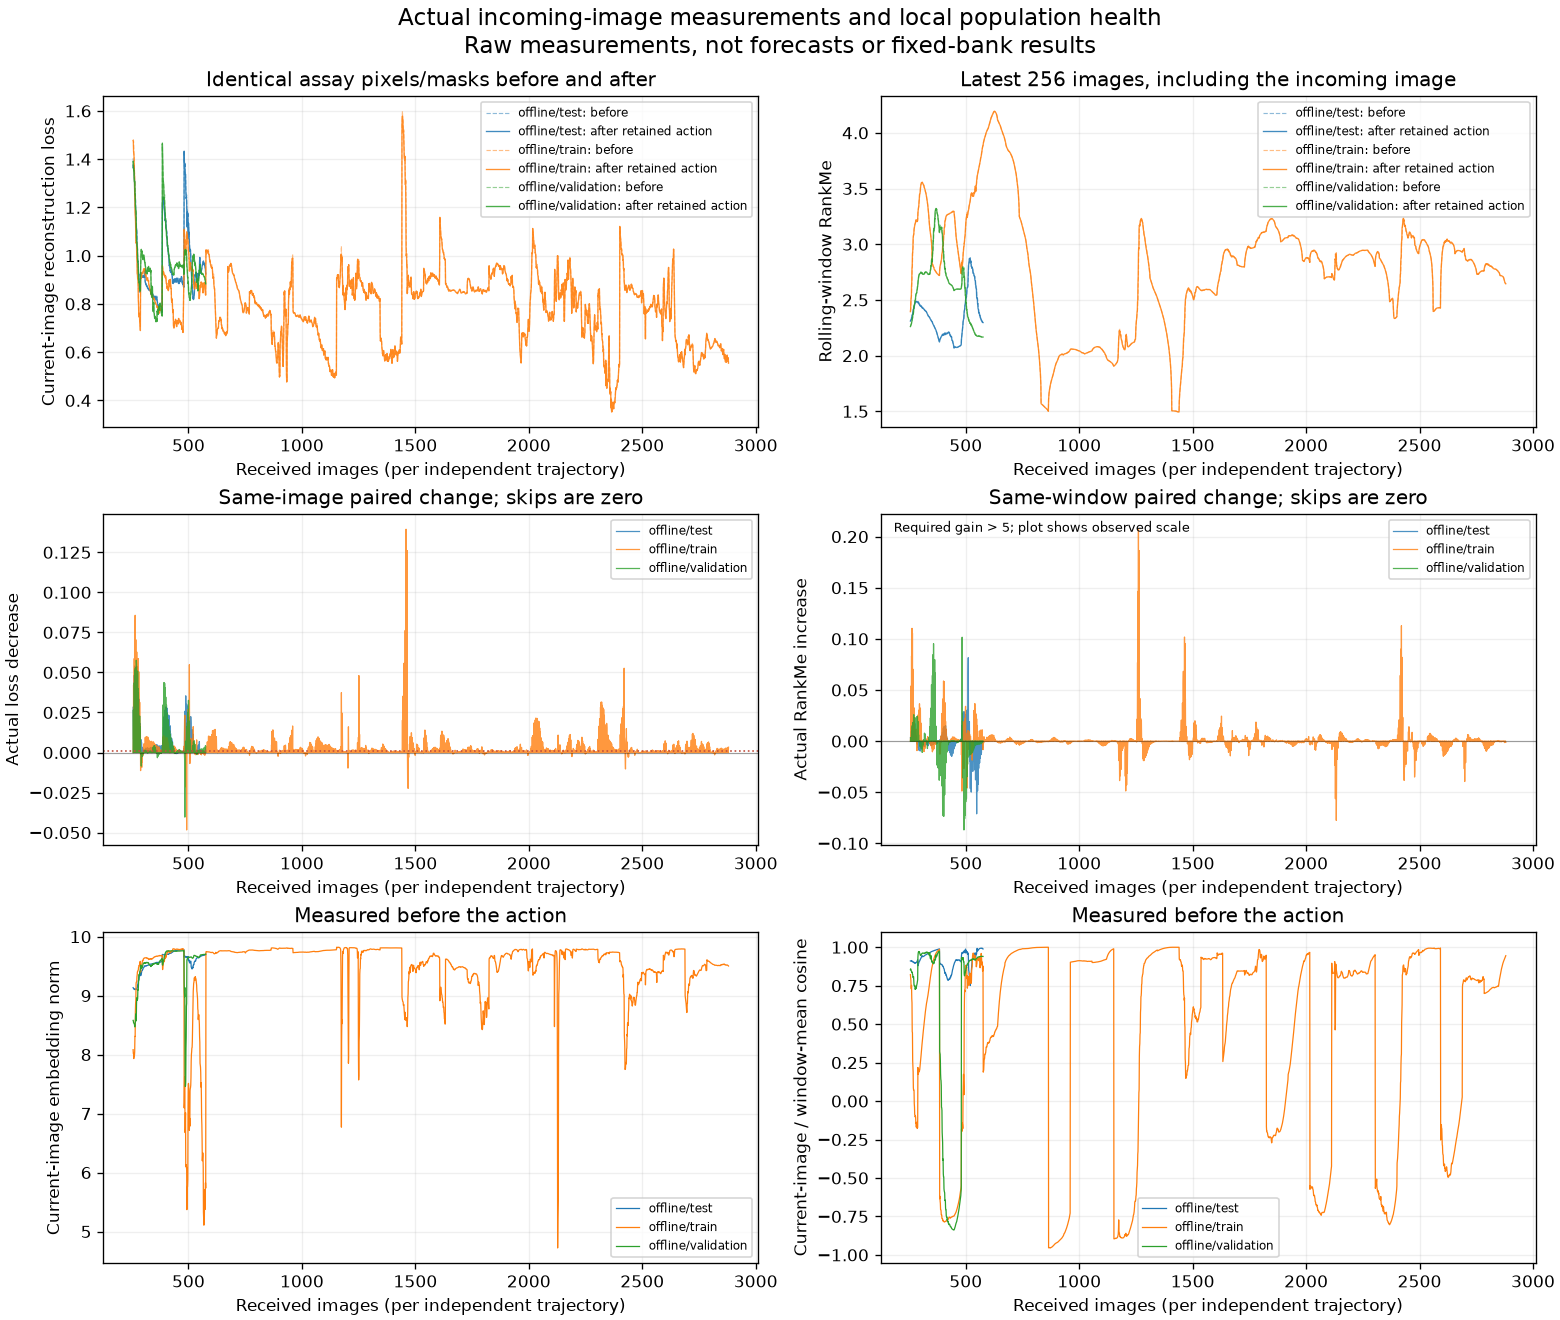

In [2]:
from IPython.display import Image, display
display(Image(filename=str(root / 'current-image-health.png')))


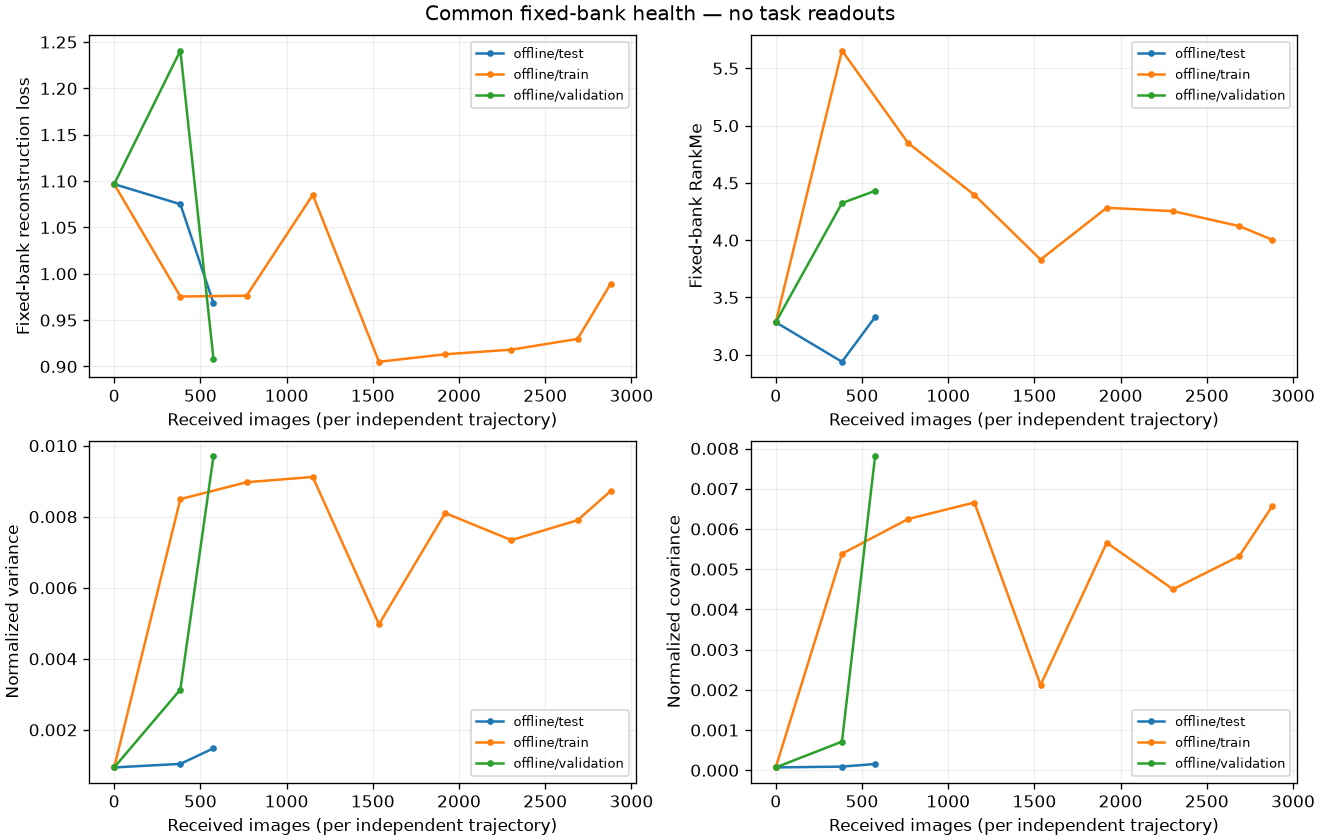

In [3]:
from IPython.display import Image, display
display(Image(filename=str(root / 'health.png')))


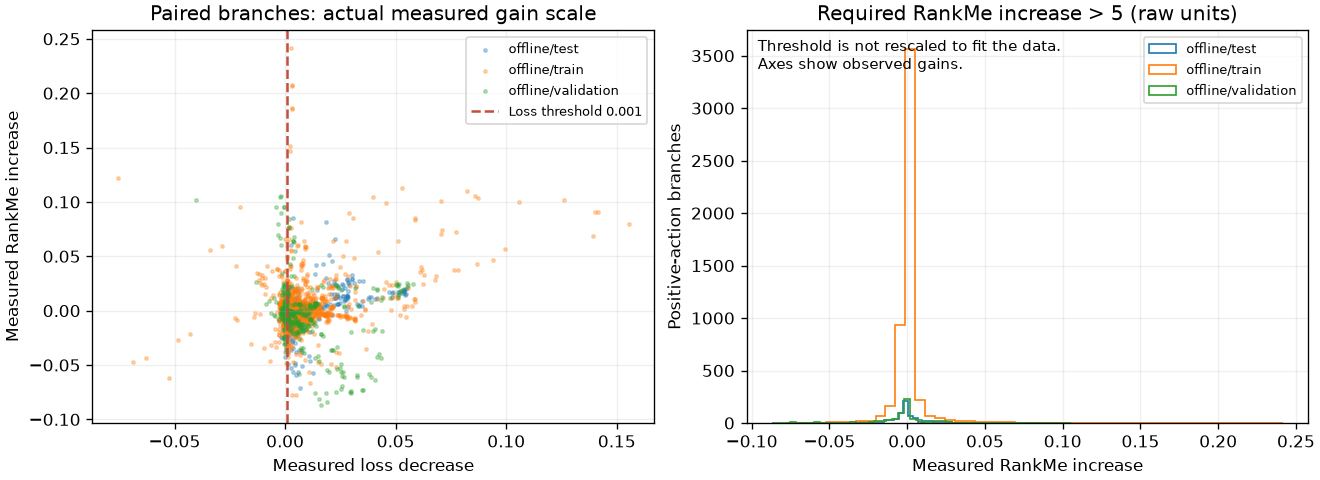

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root / 'paired-gains.png')))
